# 📊 Dataset Information

**Note:** The dataset for this project is **not included in this repository** to keep the repository lightweight.  

You can download the dataset from **Kaggle** using the link below:  

[Download The Auto Insurance Dataset](https://www.kaggle.com/datasets/generaterealdata/synthetic-auto-insurance-claims?select=vehicles.csv)  

Please make sure to place the downloaded CSV file in the same directory as this notebook before running any code.

# Importing

## Import Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

## Import CSV And convert to DataFrame

In [2]:
df = pd.read_csv('vehicles.csv')

# Preprocessing

## Frist five row

In [3]:
df.head()

,vehicle_id,vin,make,model,model_year,body_type,market_value
0,1,1XF8UAHE6JR4PH2JK,Chevrolet,Equinox,2010,suv,11442.32
1,2,K7YAR6SS2LEYJCG5K,Toyota,Corolla,2022,sedan,78705.04
2,3,485N3CBA88RLXEYZF,Toyota,Tacoma,2025,pickup,23030.52
3,4,C10FW1E05473N4AX8,Honda,CR-V,2020,suv,11107.36
4,5,RFT8DHPY3J7F7SFKP,Ford,Mustang,2018,coupe,25534.68


## last Five row

In [4]:
df.tail()

,vehicle_id,vin,make,model,model_year,body_type,market_value
36995,36996,5CCSTXL76BDRN6PPS,Mazda,CX-5,2024,suv,75370.11
36996,36997,4WBKV8YM0DR6J9ML9,Honda,Accord,2022,sedan,38390.99
36997,36998,UH5TUEG4X2FG7P396,Kia,Sportage,2019,suv,10241.07
36998,36999,7CJW2JJY8TSNVRSR5,Chevrolet,Silverado,2021,pickup,27343.74
36999,37000,FM5X45C67M4TCGJYT,Honda,Accord,2017,sedan,17991.23


## Shape of our dataset

In [5]:
df.shape

(37000, 7)

## List out all columns

In [6]:
df.columns

Index(['vehicle_id', 'vin', 'make', 'model', 'model_year', 'body_type',
       'market_value'],
      dtype='object')

## Datatype of each columns

In [7]:
df.dtypes

vehicle_id        int64
vin              object
make             object
model            object
model_year        int64
body_type        object
market_value    float64
dtype: object

## Information of all Columns

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 37000 entries, 0 to 36999
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   vehicle_id    37000 non-null  int64  
 1   vin           37000 non-null  object 
 2   make          37000 non-null  object 
 3   model         37000 non-null  object 
 4   model_year    37000 non-null  int64  
 5   body_type     37000 non-null  object 
 6   market_value  37000 non-null  float64
dtypes: float64(1), int64(2), object(4)
memory usage: 2.0+ MB


## Check Null Value

In [9]:
df.isnull().sum()

vehicle_id      0
vin             0
make            0
model           0
model_year      0
body_type       0
market_value    0
dtype: int64

## Check Dupicate Value

In [10]:
df.duplicated().sum()

np.int64(0)

## Summary

In [11]:
df.describe()

,vehicle_id,model_year,market_value
count,37000.000000,37000.000000,37000.000000
mean,18500.500000,2019.077459,32165.261678
std,10681.124317,4.939735,22020.312518
min,1.000000,2008.000000,3000.550000
25%,9250.750000,2016.000000,13004.290000
50%,18500.500000,2020.000000,27992.405000
75%,27750.250000,2023.000000,44587.970000
max,37000.000000,2026.000000,84988.700000


# EDA

In [12]:
def show_fig():
    plt.tight_layout()
    plt.show()

plot_no = 1

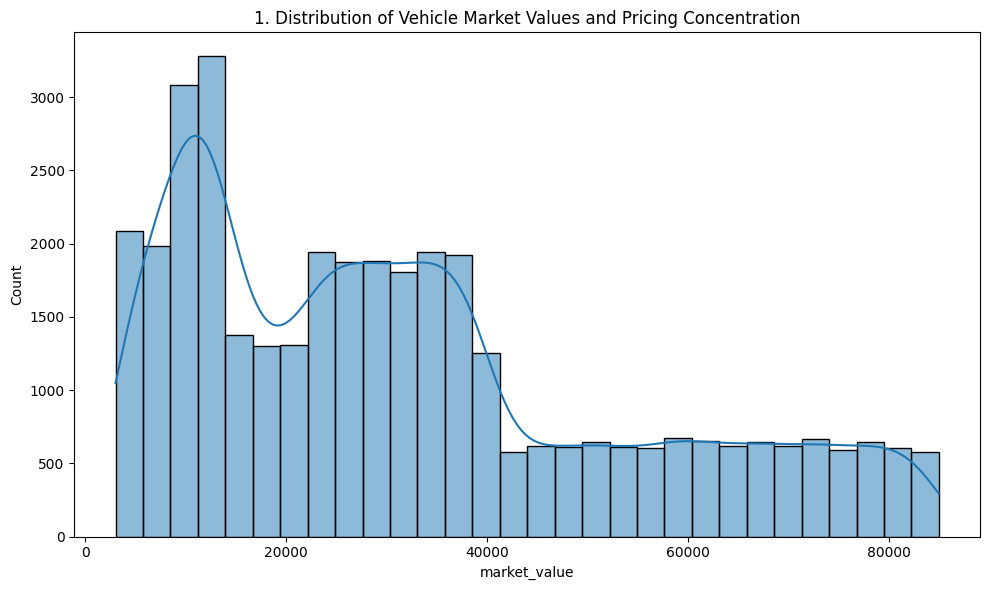

In [13]:
fig = plt.figure(figsize=(10,6))
sns.histplot(data=df, x='market_value', bins=30, kde=True)
plt.title(f'{plot_no}. Distribution of Vehicle Market Values and Pricing Concentration')
show_fig()
plot_no += 1

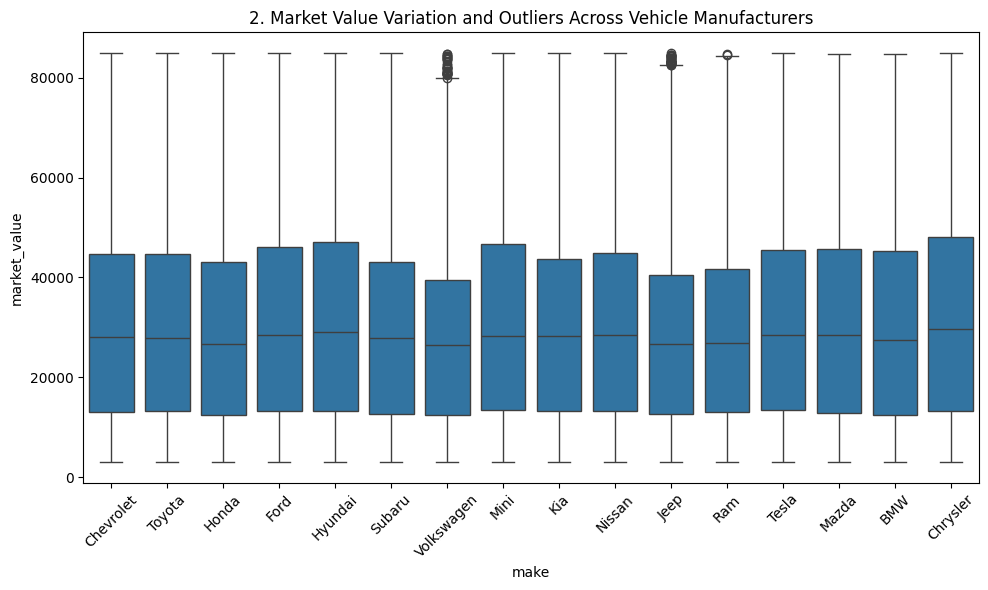

In [14]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='make', y='market_value')
plt.title(f'{plot_no}. Market Value Variation and Outliers Across Vehicle Manufacturers')
plt.xticks(rotation=45)
show_fig()
plot_no += 1

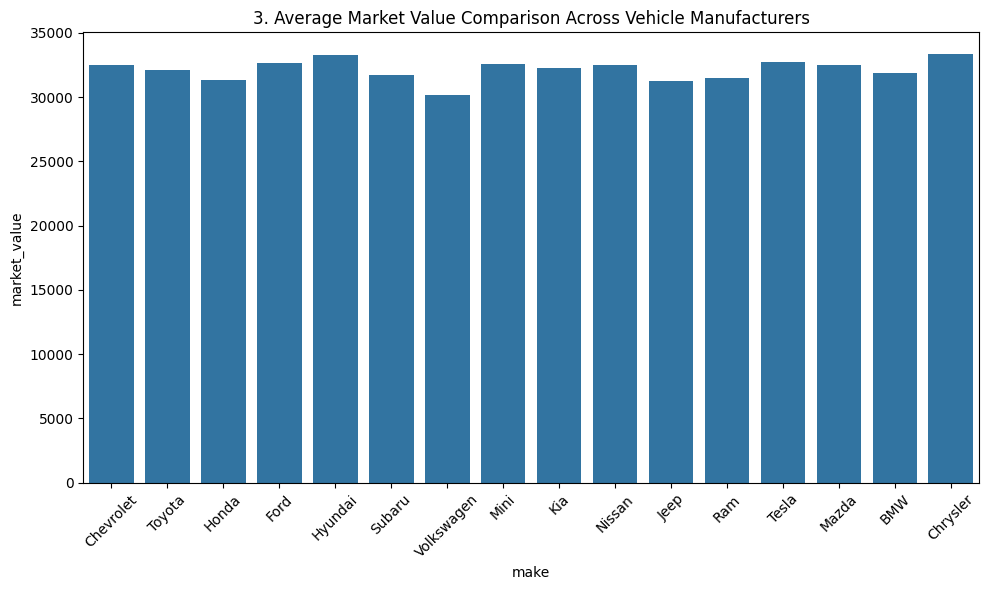

In [15]:
fig = plt.figure(figsize=(10,6))
sns.barplot(data=df, x='make', y='market_value', estimator='mean', errorbar=None)
plt.title(f'{plot_no}. Average Market Value Comparison Across Vehicle Manufacturers')
plt.xticks(rotation=45)
show_fig()
plot_no += 1

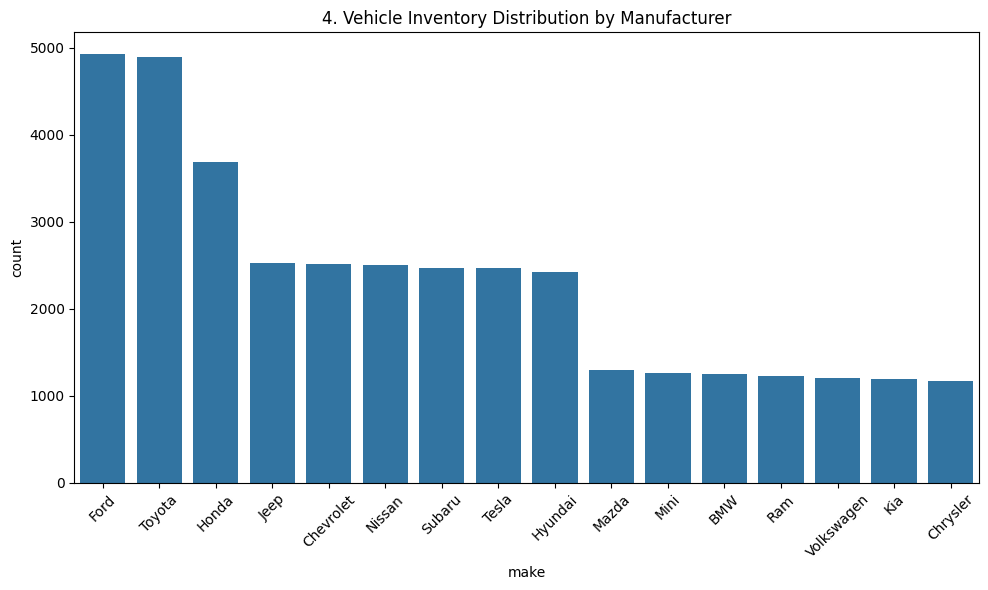

In [16]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='make', order=df['make'].value_counts().index)
plt.title(f'{plot_no}. Vehicle Inventory Distribution by Manufacturer')
plt.xticks(rotation=45)
show_fig()
plot_no += 1

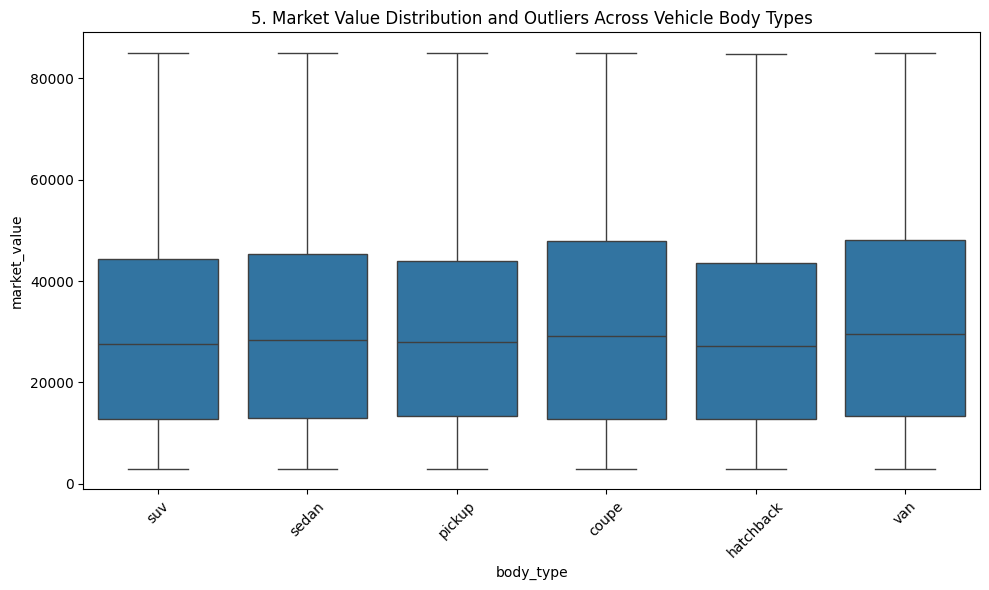

In [17]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='body_type', y='market_value')
plt.title(f'{plot_no}. Market Value Distribution and Outliers Across Vehicle Body Types')
plt.xticks(rotation=45)
show_fig()
plot_no += 1

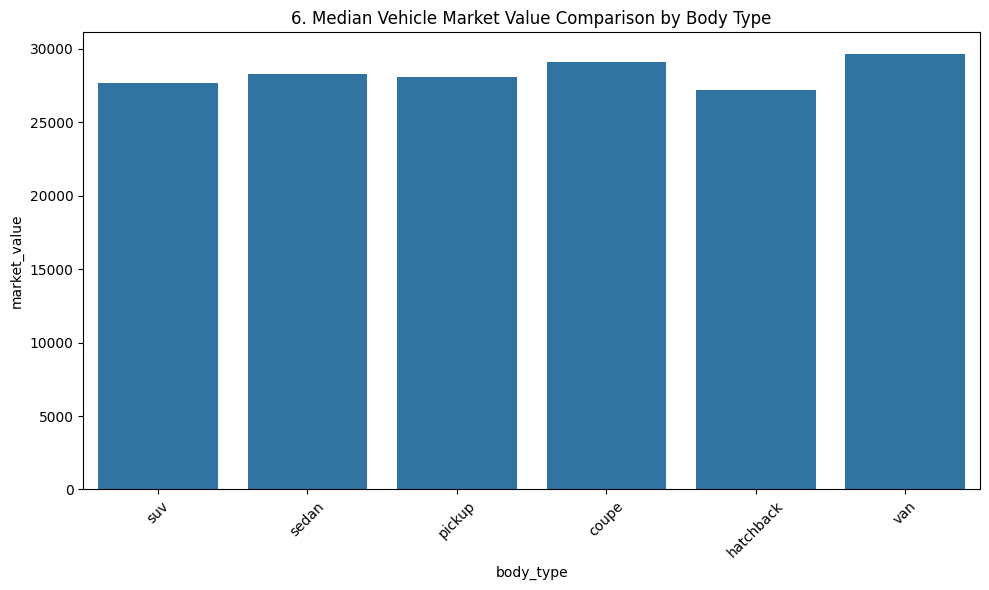

In [18]:
fig = plt.figure(figsize=(10,6))
sns.barplot(data=df, x='body_type', y='market_value', estimator='median', errorbar=None)
plt.title(f'{plot_no}. Median Vehicle Market Value Comparison by Body Type')
plt.xticks(rotation=45)
show_fig()
plot_no += 1

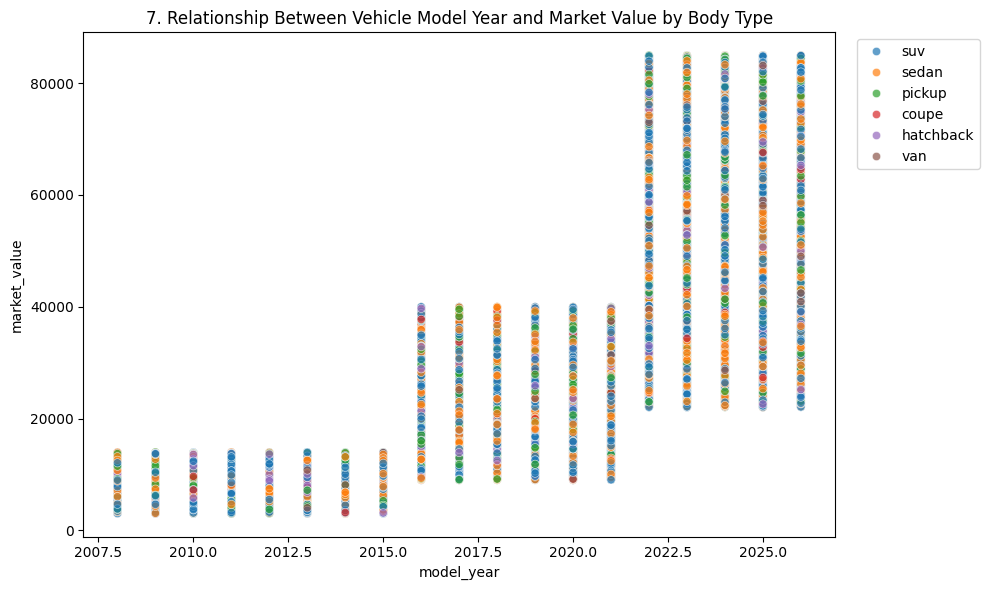

In [19]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='model_year', y='market_value', hue='body_type', alpha=0.7)
plt.title(f'{plot_no}. Relationship Between Vehicle Model Year and Market Value by Body Type')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
show_fig()
plot_no += 1

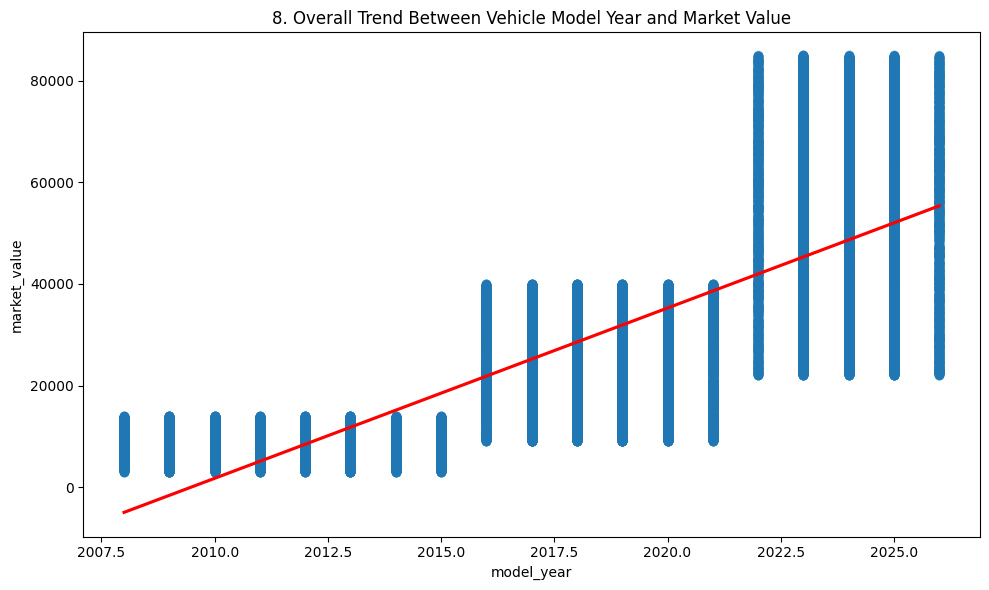

In [20]:
fig = plt.figure(figsize=(10,6))
sns.regplot(data=df, x='model_year', y='market_value', scatter_kws={'alpha':0.4}, line_kws={'color':'red'})
plt.title(f'{plot_no}. Overall Trend Between Vehicle Model Year and Market Value')
show_fig()
plot_no += 1

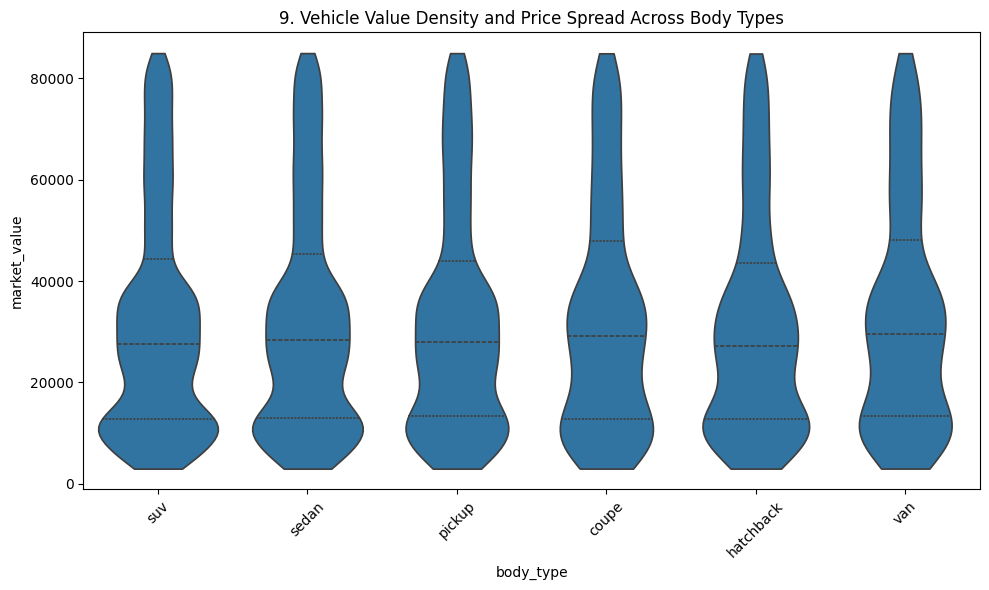

In [21]:
fig = plt.figure(figsize=(10,6))
sns.violinplot(data=df, x='body_type', y='market_value', inner='quartile', cut=0)
plt.title(f'{plot_no}. Vehicle Value Density and Price Spread Across Body Types')
plt.xticks(rotation=45)
show_fig()
plot_no += 1

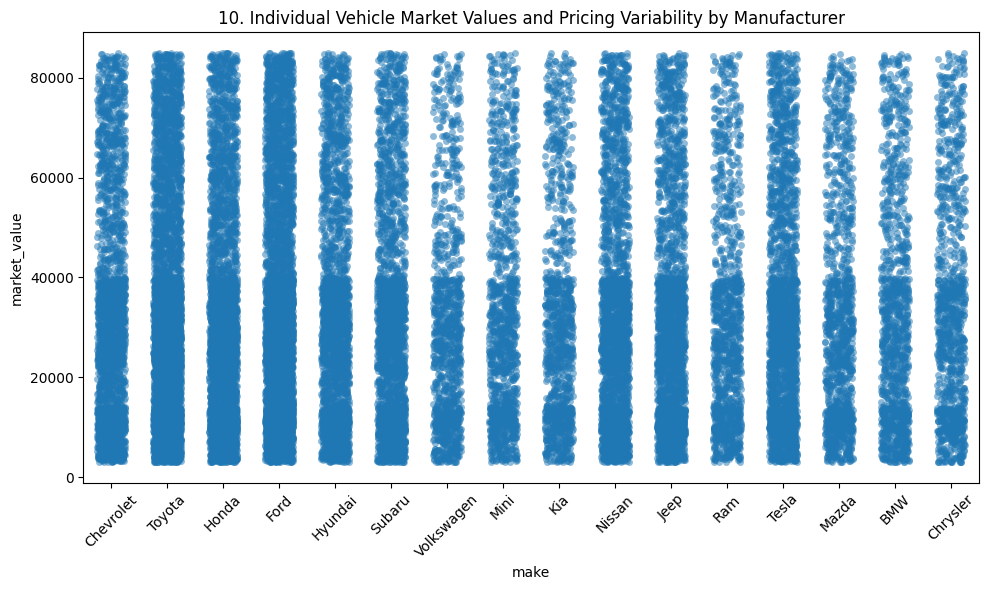

In [22]:
fig = plt.figure(figsize=(10,6))
sns.stripplot(data=df, x='make', y='market_value', alpha=0.5, jitter=0.25)
plt.title(f'{plot_no}. Individual Vehicle Market Values and Pricing Variability by Manufacturer')
plt.xticks(rotation=45)
show_fig()
plot_no += 1

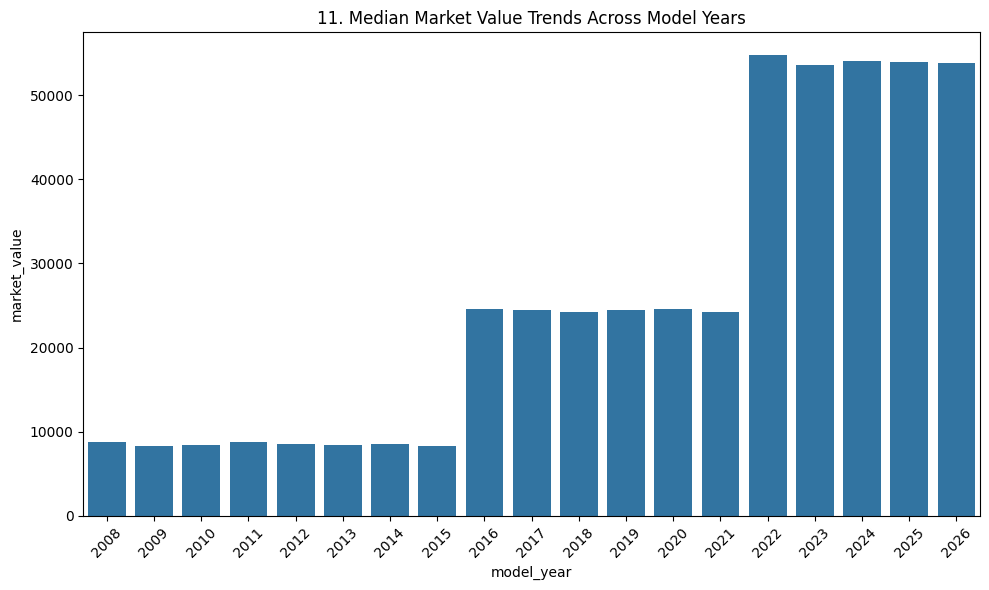

In [23]:
fig = plt.figure(figsize=(10,6))
sns.barplot(data=df, x='model_year', y='market_value', estimator='median', errorbar=None)
plt.title(f'{plot_no}. Median Market Value Trends Across Model Years')
plt.xticks(rotation=45)
show_fig()
plot_no += 1

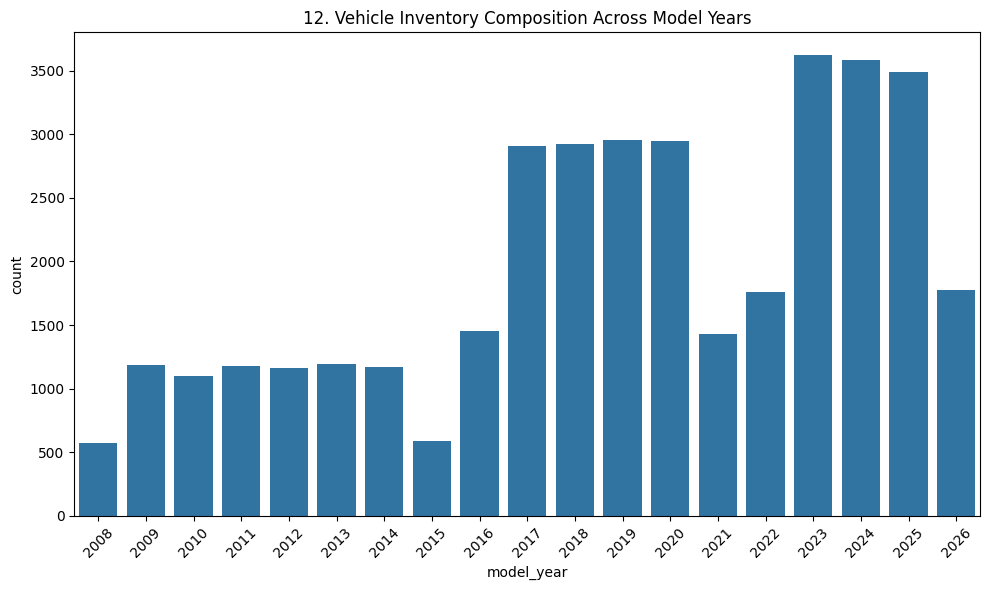

In [24]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='model_year', order=sorted(df['model_year'].dropna().unique()))
plt.title(f'{plot_no}. Vehicle Inventory Composition Across Model Years')
plt.xticks(rotation=45)
show_fig()
plot_no += 1

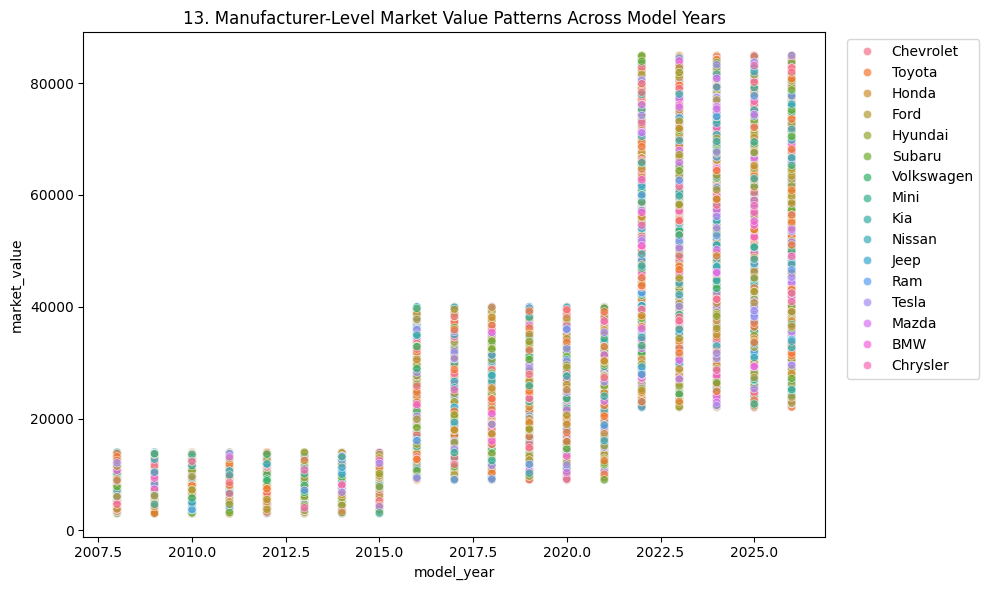

In [25]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='model_year', y='market_value', hue='make', alpha=0.7)
plt.title(f'{plot_no}. Manufacturer-Level Market Value Patterns Across Model Years')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
show_fig()
plot_no += 1

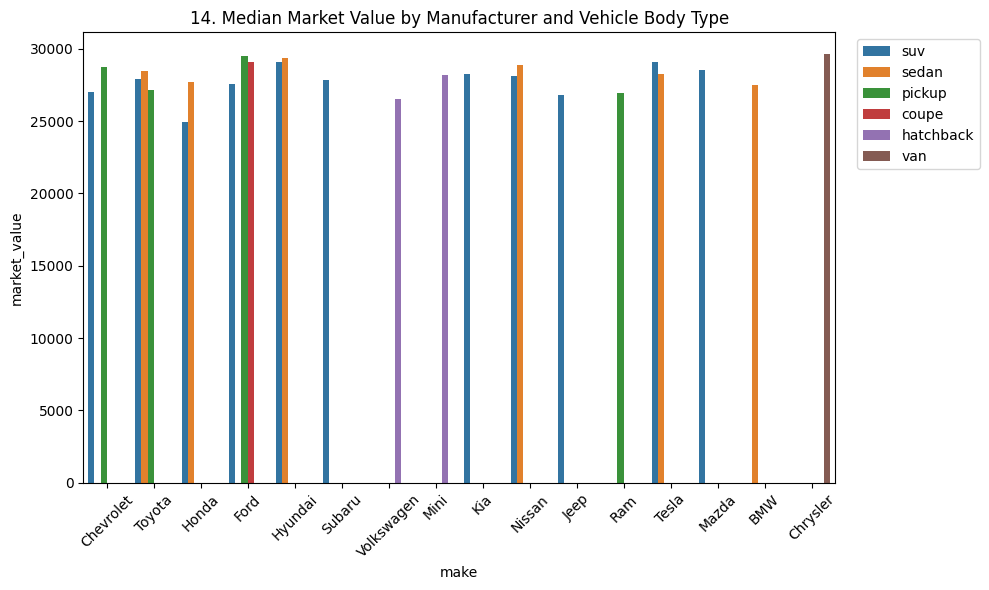

In [26]:
fig = plt.figure(figsize=(10,6))
sns.barplot(data=df, x='make', y='market_value', hue='body_type', estimator='median', errorbar=None)
plt.title(f'{plot_no}. Median Market Value by Manufacturer and Vehicle Body Type')
plt.xticks(rotation=45)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
show_fig()
plot_no += 1

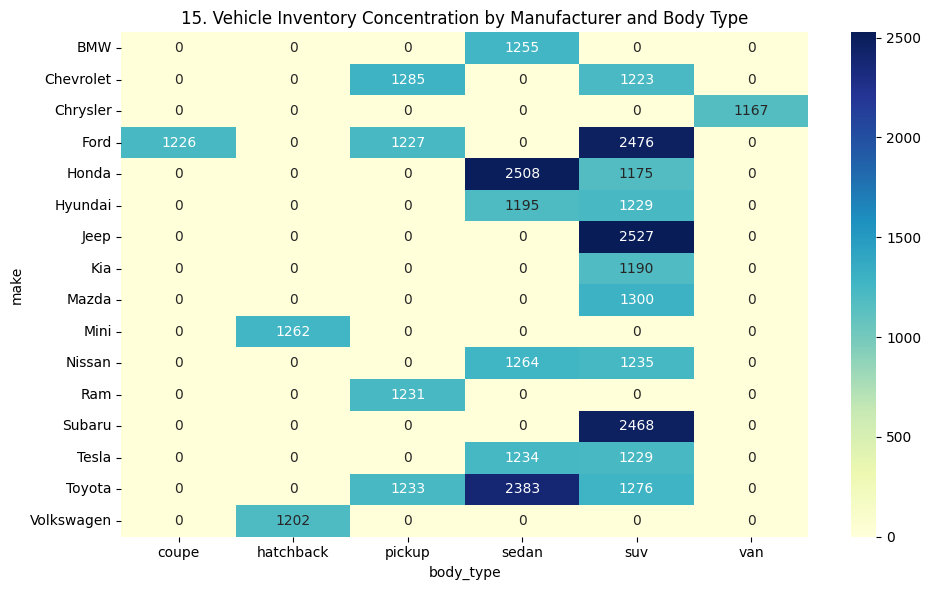

In [27]:
fig = plt.figure(figsize=(10,6))
sns.heatmap(pd.crosstab(df['make'], df['body_type']), annot=True, fmt='d', cmap='YlGnBu')
plt.title(f'{plot_no}. Vehicle Inventory Concentration by Manufacturer and Body Type')
show_fig()
plot_no += 1

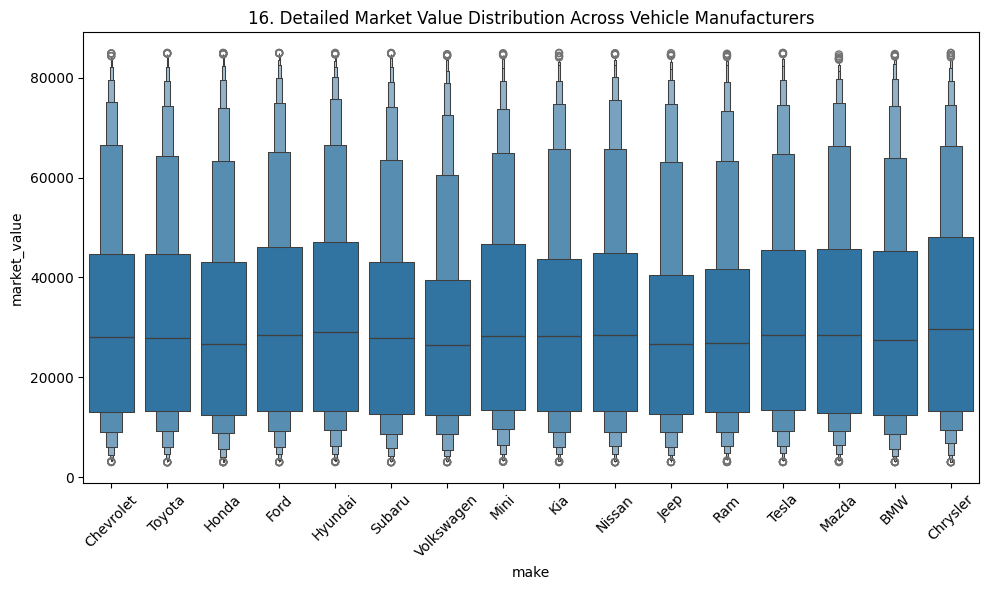

In [28]:
fig = plt.figure(figsize=(10,6))
sns.boxenplot(data=df, x='make', y='market_value')
plt.title(f'{plot_no}. Detailed Market Value Distribution Across Vehicle Manufacturers')
plt.xticks(rotation=45)
show_fig()
plot_no += 1

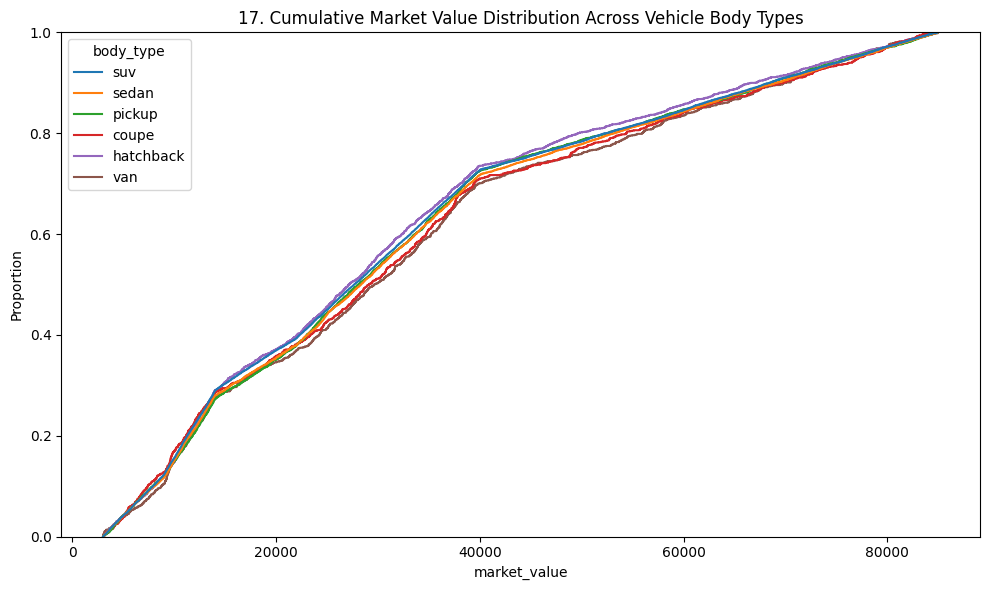

In [29]:
fig = plt.figure(figsize=(10,6))
sns.ecdfplot(data=df, x='market_value', hue='body_type')
plt.title(f'{plot_no}. Cumulative Market Value Distribution Across Vehicle Body Types')
show_fig()
plot_no += 1

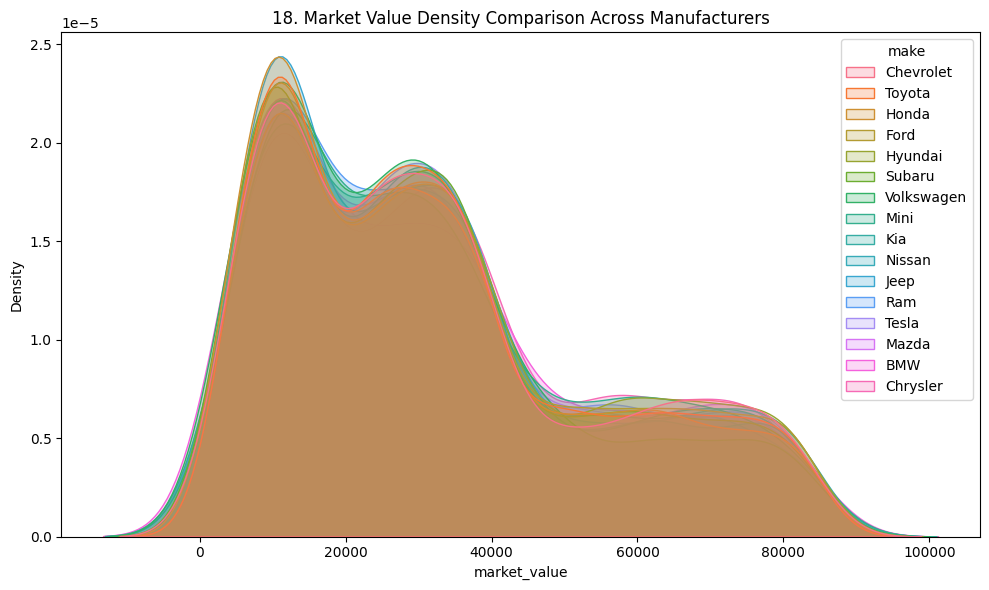

In [30]:
fig = plt.figure(figsize=(10,6))
sns.kdeplot(data=df, x='market_value', hue='make', fill=True, common_norm=False, alpha=0.25)
plt.title(f'{plot_no}. Market Value Density Comparison Across Manufacturers')
show_fig()
plot_no += 1

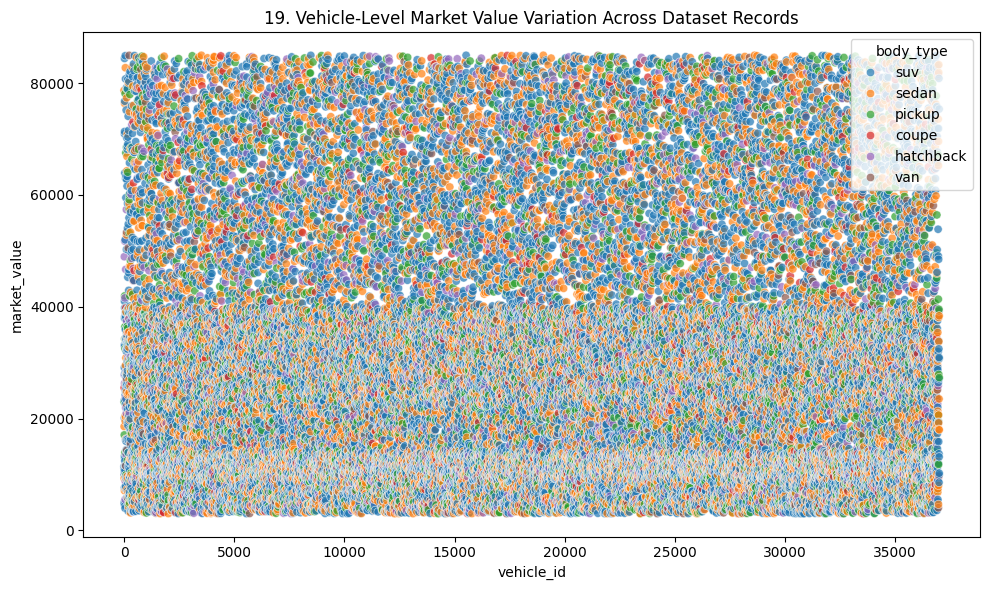

In [31]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='vehicle_id', y='market_value', hue='body_type', alpha=0.7)
plt.title(f'{plot_no}. Vehicle-Level Market Value Variation Across Dataset Records')
show_fig()
plot_no += 1

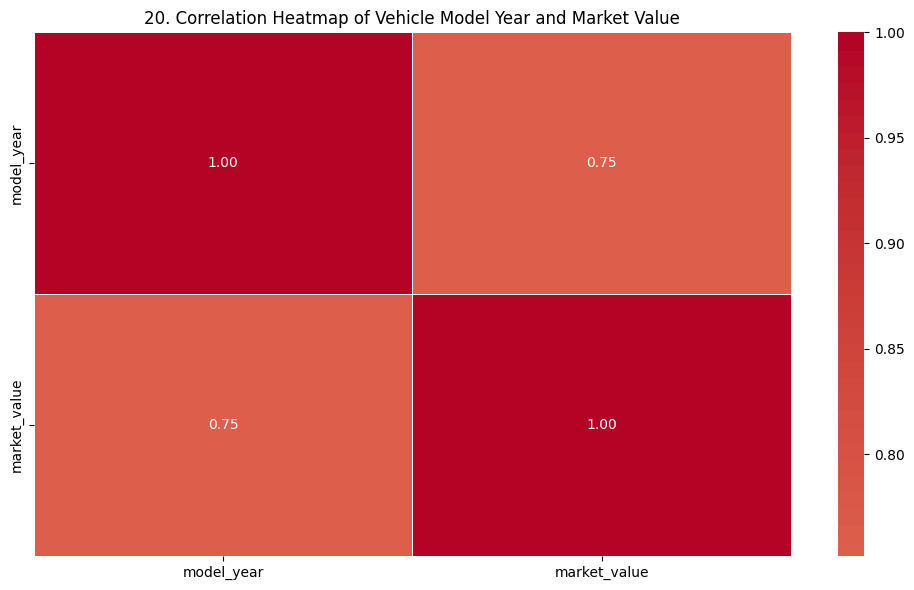

In [32]:
fig = plt.figure(figsize=(10,6))
corr = df.select_dtypes(include='number').drop(columns=['vehicle_id'], errors='ignore').corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5, center=0)
plt.title(f'{plot_no}. Correlation Heatmap of Vehicle Model Year and Market Value')
show_fig()
plot_no += 1